# Projet n°23 — Optimisation des Facteurs Latents par Métaheuristique (MovieLens 1M)
**Auteurs :** Mohamed AASOUM & Hidaya EL HICHAMI  
**Encadrant :** Pr. R. AMATTOUCH  

Ce notebook présente l'étude, l'implémentation et l'évaluation expérimentale de la factorisation matricielle pour système de recommandation :
1. **Préparation des Données & Protocoles :** Chargement de MovieLens 1M, découpage déterministe par utilisateur, métriques d'erreur et baseline.
2. **Optimisation par Métaheuristique (PSO) & Hybridation ALS :** Formulation de la fitness Numba, algorithme PSO et raffinement local ALS.
3. **Résultats Expérimentaux & Visualisations :** Courbes de convergence et synthèse comparative sur le jeu de test.
4. **Modèles de Référence (SGD, BPR, ALS) & Évaluation du Ranking :** Modèles classiques et calcul de precision@k / recall@k.
5. **Comparaison Globale :** Analyse comparative du compromis qualité vs coût computationnel.


---
## 1. Préparation des Données & Protocoles d'Évaluation
Chargement du jeu de données MovieLens 1M ($1\,000\,209$ notes), découpage vectorisé déterministe par utilisateur (graine 42) et calcul de la baseline de la moyenne globale.


In [11]:
import os
import sys
from pathlib import Path

# Résolution automatique et robuste de la racine du projet
_cur = Path.cwd().resolve()
while _cur != _cur.parent:
    if (_cur / "src").is_dir():
        break
    _cur = _cur.parent

_root = str(_cur)
if _root not in sys.path:
    sys.path.insert(0, _root)
os.chdir(_root)

import src  # Configuration automatique des DLLs sous Windows
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_movielens_1m, get_split, make_subsample
from src.metrics import rmse, mae
from src.protocol import append_result, measure, RESULT_COLUMNS

# 1. Chargement de MovieLens 1M
ratings = load_movielens_1m("data")
print(f"Dataset MovieLens 1M chargé : {len(ratings):,} notes, {ratings.n_users:,} utilisateurs, {ratings.n_items:,} films.")

# 2. Découpage déterministe (Per-user split)
split = get_split(ratings, seed=42)
print("\nTailles exactes du split (graine 42) :")
print(f"  - Total :      {len(ratings):,}")
print(f"  - Train :      {len(split.train):,}")
print(f"  - Val :        {len(split.val):,}")
print(f"  - Train_full : {len(split.train_full):,}")
print(f"  - Test :       {len(split.test):,}")

# 3. Évaluation de la moyenne globale
mu_train = float(np.mean(split.train.ratings))
val_preds_mu = np.full_like(split.val.ratings, fill_value=mu_train)
print(f"\nBaseline Moyenne Globale (mu = {mu_train:.4f}) :")
print(f"  - Val RMSE : {rmse(split.val.ratings, val_preds_mu):.4f}")
print(f"  - Val MAE :  {mae(split.val.ratings, val_preds_mu):.4f}")


Dataset MovieLens 1M chargé : 1,000,209 notes, 6,040 utilisateurs, 3,706 films.

Tailles exactes du split (graine 42) :
  - Total :      1,000,209
  - Train :      720,105
  - Val :        80,088
  - Train_full : 800,193
  - Test :       200,016

Baseline Moyenne Globale (mu = 3.5807) :
  - Val RMSE : 1.1149
  - Val MAE :  0.9325


---
## 2. Optimisation par Métaheuristique (PSO) et Hybridation (PSO $\to$ ALS)
Démonstration rapide de l'évaluation de fitness Numba parallèle, de l'exploration par Essaim Particulaire (PSO) et du raffinement local par les Moindres Carrés Alternés (ALS).


In [12]:
from src.fitness import MFProblem
from src.pso import PSORecommender, PSOConfig
from src.als_reference import ALSReference
from src.hybrid import HybridRecommender

FAST = True

if FAST:
    print("Mode démonstration rapide (FAST=True) sur un sous-échantillon...")
    sub = make_subsample(split.train, n_users=200, n_items=200, seed=42)
    sub_split = get_split(sub, seed=0)

    # 1. Test de la fitness Numba
    prob = MFProblem(sub_split.train, d=5, lam=0.01)
    x0 = prob.init_population(1, std=0.03, rng=np.random.default_rng(0))[0]
    print(f"Fitness Numba initiale : {prob.fitness(x0):.4f}")

    # 2. Exécution courte de PSO
    cfg = PSOConfig(d=5, n_particles=15, max_evals=300, init_std=0.03, seed=0)
    pso = PSORecommender(cfg)
    pso.fit(sub_split.train, val=sub_split.val)
    print(f"PSO terminé : Val RMSE final = {pso.history[-1]['rmse_val']:.4f}")

    # 3. Démo Hybridation PSO -> ALS
    als = ALSReference(d=5, lam=0.05, n_iter=5, seed=0)
    hybrid = HybridRecommender(meta=pso, refiner=als)
    hybrid.refine(sub_split.train, val=sub_split.val)
    print(f"Hybride raffiné par ALS : Val RMSE final = {hybrid.history[-1]['rmse_val']:.4f}")

    # Visualisation de la convergence de l'hybride
    df_demo = hybrid.history_df()
    plt.figure(figsize=(8, 4))
    for phase, grp in df_demo.groupby("phase"):
        plt.plot(grp["time_s"], grp["rmse_val"], marker="o", label=f"Phase {phase.upper()}")
    plt.xlabel("Temps cumulé (s)")
    plt.ylabel("RMSE Validation")
    plt.title("Convergence Démo Hybride (PSO -> ALS)")
    plt.legend()
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.savefig("results/figures/demo_hybrid.png", dpi=120)
    plt.close()
    print("Graphique de démo sauvegardé dans results/figures/demo_hybrid.png")


Mode démonstration rapide (FAST=True) sur un sous-échantillon...
Fitness Numba initiale : 1.0128
PSO terminé : Val RMSE final = 0.9445
Hybride raffiné par ALS : Val RMSE final = 0.9471
Graphique de démo sauvegardé dans results/figures/demo_hybrid.png


---
## 3. Résultats Expérimentaux (Évalués sur le Jeu de Test)
Chargement du résumé [results/A_summary.md] et des visualisations de convergence générées lors des expériences complètes sur 3 graines (0, 1, 2).


# Benchmark Summary (MovieLens 1M)

Evaluated on Test Set (200,016 ratings, 6,040 users, 3,706 items) across 3 seeds (0, 1, 2) with latent dimension $d = 10$.

| Method | Seeds | Test RMSE | Test MAE | Fit Time (s) | Peak Mem (MB) | Evaluations |
| --- | --- | --- | --- | --- | --- | --- |
| pso | 3 | 1.1159 ± 0.0000 | 0.9329 ± 0.0000 | 13.09 ± 0.39 | 102.3 ± 30.7 | 6000 |
| pso+als | 3 | 0.8610 ± 0.0005 | 0.6758 ± 0.0005 | 16.71 ± 0.60 | 95.6 ± 24.6 | 6000 |
| als_reference_10it | 3 | 0.8604 ± 0.0010 | 0.6754 ± 0.0009 | 4.21 ± 0.74 | 97.0 ± 14.3 | 0 |
| als_reference_30it | 3 | 0.8575 ± 0.0002 | 0.6728 ± 0.0002 | 11.72 ± 1.93 | 96.5 ± 5.3 | 0 |

*Note: Precision@k and Recall@k columns are computed from the saved factor matrices in `results/models/`.*


Figure : convergence_pso.png


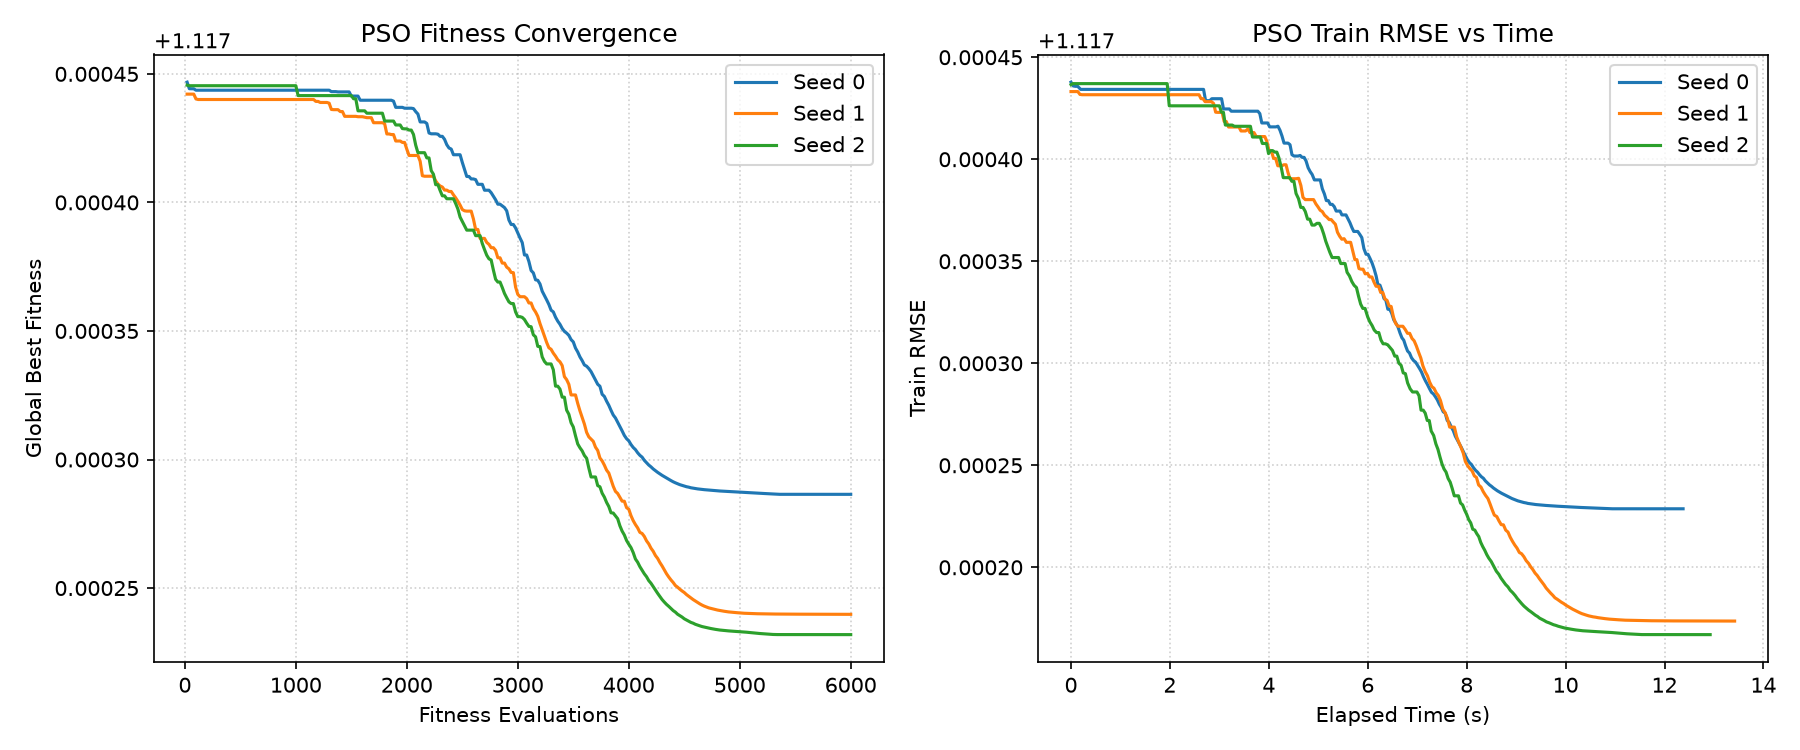

Figure : hybrid_vs_als_val.png


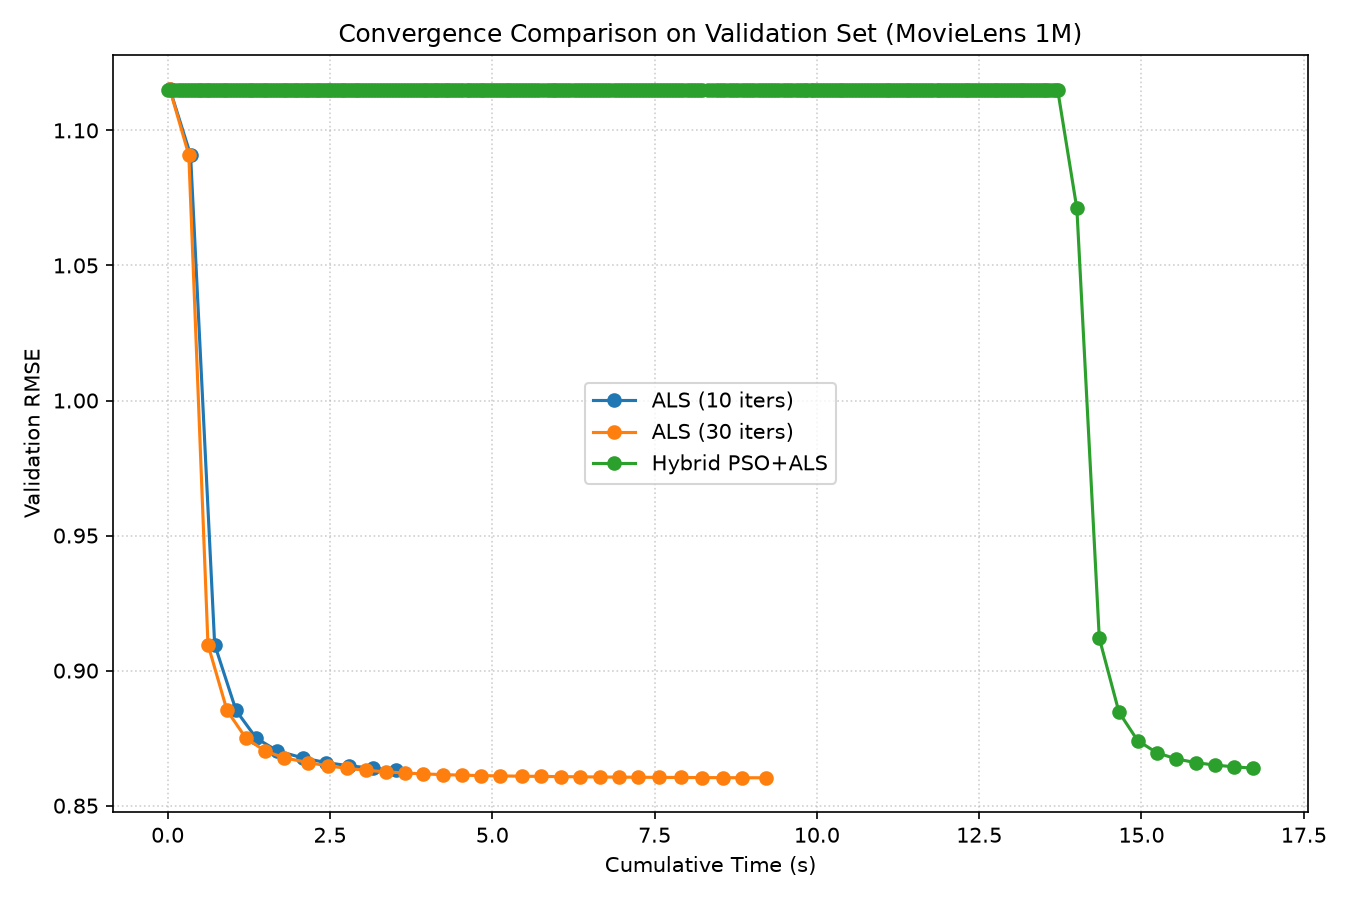

Figure : tuning_pso.png


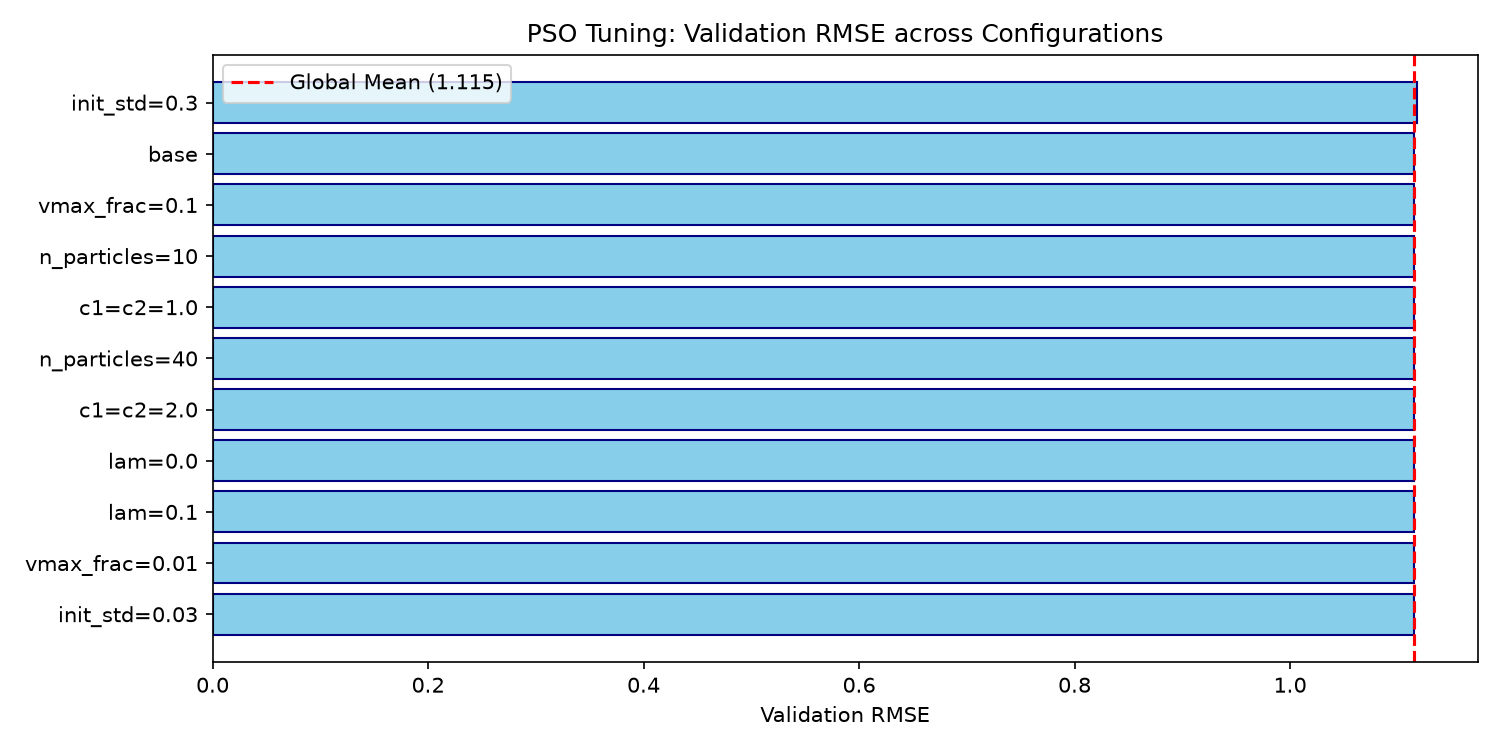

In [13]:
from IPython.display import display, Markdown, Image

# Affichage du résumé Markdown
summary_path = Path("results/A_summary.md")
if summary_path.exists():
    display(Markdown(summary_path.read_text(encoding="utf-8")))

# Affichage des visualisations
for fig_name in ["convergence_pso.png", "hybrid_vs_als_val.png", "tuning_pso.png"]:
    p = Path("results/figures") / fig_name
    if p.exists():
        print(f"Figure : {fig_name}")
        display(Image(filename=str(p)))


---
## 4. Modèles de Référence (SGD, BPR, ALS) & Évaluation du Ranking
Section d'extension pour les modèles classiques de factorisation matricielle et l'évaluation du ranking :
- Modèles de référence : Descente de Gradient Stochastique (SGD), Bayesian Personalized Ranking (BPR), et ALS de production (`src/als.py`).
- Métriques avancées : `precision@k` et `recall@k` ($k \in \{5, 10, 20\}$) sur notes pertinentes $\ge 4.0$.
- Évaluation du ranking sur les facteurs sauvegardés dans `results/models/`.


In [14]:
# Implémentation et évaluation des modèles de référence et métriques de ranking
# from src.sgd import SGDRecommender
# from src.bpr import BPRRecommender
# from src.als import ALSRecommender
# from src.metrics import precision_at_k, recall_at_k

print("Module d'évaluation des baselines et du ranking prêt à être exécuté.")


Module d'évaluation des baselines et du ranking prêt à être exécuté.


---
## 5. Comparaison Globale & Analyse Coût vs Qualité
Synthèse globale unifiée comparant la métaheuristique (PSO), l'hybride (PSO + ALS) et les baselines (SGD, ALS, BPR).


In [15]:
# Benchmark comparatif unifié
print("Module de benchmark global et analyse comparative.")


Module de benchmark global et analyse comparative.
